In [5]:
#Import Libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [6]:
df = pd.read_csv("/content/AB_NYC_2019.csv.zip")

In [7]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [8]:
df.tail()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
48890,36484665,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,NaN,2,9
48891,36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,NaN,2,36
48892,36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,NaN,1,27
48893,36485609,43rd St. Time Square-cozy single bed,30985759,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,NaN,6,2
48894,36487245,Trendy duplex in the very heart of Hell's Kitchen,68119814,Christophe,Manhattan,Hell's Kitchen,40.76404,-73.98933,Private room,90,7,0,NaN,NaN,1,23


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df = df.drop(columns = ["neighbourhood_group","name","latitude","longitude","number_of_reviews","calculated_host_listings_count","last_review"])
df.head()

,id,host_id,host_name,neighbourhood,room_type,price,minimum_nights,reviews_per_month,availability_365
0,2539,2787,John,Kensington,Private room,149,1,0.21,365
1,2595,2845,Jennifer,Midtown,Entire home/apt,225,1,0.38,355
2,3647,4632,Elisabeth,Harlem,Private room,150,3,NaN,365
3,3831,4869,LisaRoxanne,Clinton Hill,Entire home/apt,89,1,4.64,194
4,5022,7192,Laura,East Harlem,Entire home/apt,80,10,0.10,0


In [12]:
df.isnull().sum()

,0
id,0
host_id,0
host_name,21
neighbourhood,0
room_type,0
price,0
minimum_nights,0
reviews_per_month,10052
availability_365,0


In [13]:
df['host_name'] = df['host_name'].fillna(df['host_name'].mode().iloc())
df['reviews_per_month'] = df['reviews_per_month'].fillna(df['reviews_per_month'].median())

In [14]:
df.isnull().sum()

,0
id,0
host_id,0
host_name,0
neighbourhood,0
room_type,0
price,0
minimum_nights,0
reviews_per_month,0
availability_365,0


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 48895 non-null  int64  
 1   host_id            48895 non-null  int64  
 2   host_name          48895 non-null  object 
 3   neighbourhood      48895 non-null  object 
 4   room_type          48895 non-null  object 
 5   price              48895 non-null  int64  
 6   minimum_nights     48895 non-null  int64  
 7   reviews_per_month  48895 non-null  float64
 8   availability_365   48895 non-null  int64  
dtypes: float64(1), int64(5), object(3)
memory usage: 3.4+ MB


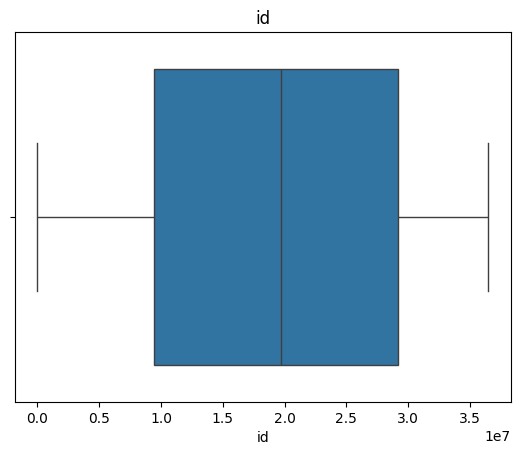

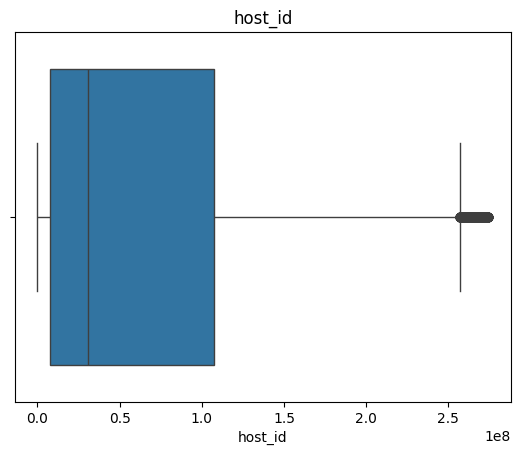

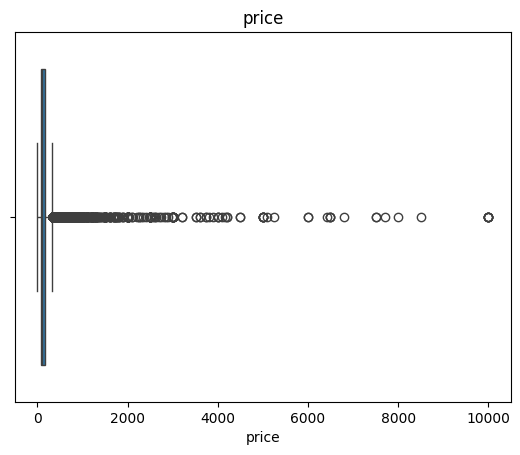

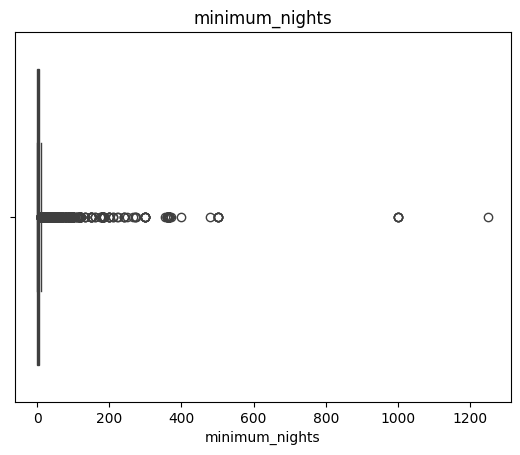

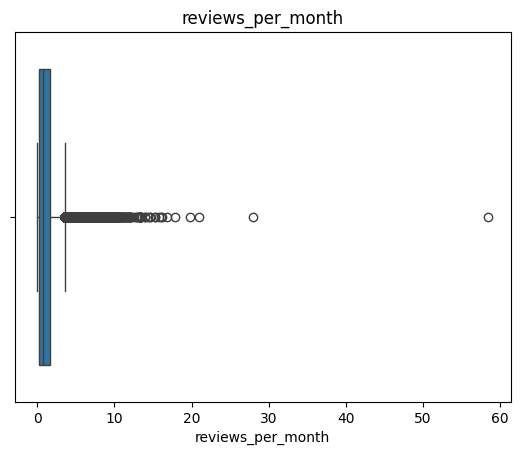

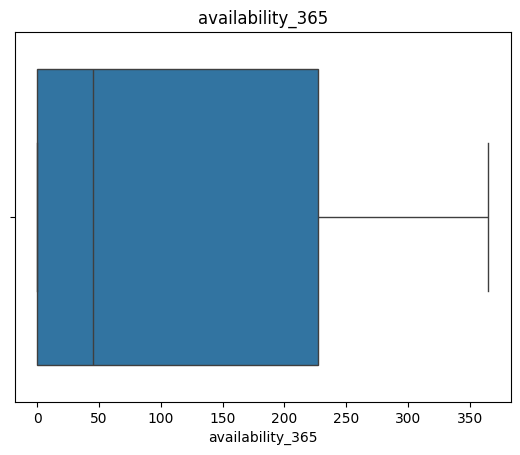

In [16]:
for col in df.select_dtypes(include = 'number').columns:
  sns.boxplot(x = df[col])
  plt.title(col)
  plt.show()

In [17]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q1 - Q3
lower_bound = Q1 -1.5 * IQR
upper_bound = Q3 +1.5 * IQR
df['price'] = df['price'].clip(lower_bound, upper_bound)

In [18]:
Q1 = df['minimum_nights'].quantile(0.25)
Q3 = df['minimum_nights'].quantile(0.75)
IQR = Q1 - Q3
lower_bound = Q1 -1.5 * IQR
upper_bound = Q3 +1.5 * IQR
df['minimum_nights'] = df['minimum_nights'].clip(lower_bound, upper_bound)

<Axes: xlabel='price'>

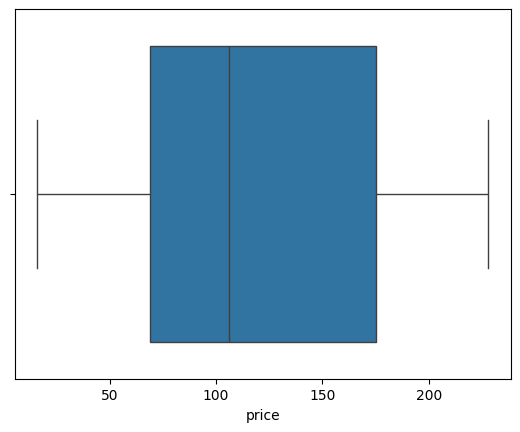

In [19]:
sns.boxplot(x = df['price'])

<Axes: xlabel='minimum_nights'>

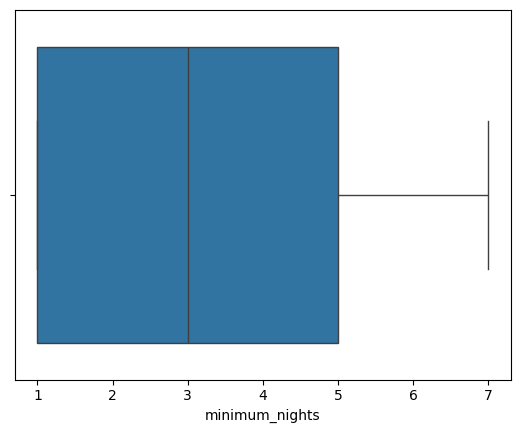

In [20]:
sns.boxplot(x = df['minimum_nights'])

/tmp/ipykernel_31671/2729941190.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x = df['id'])


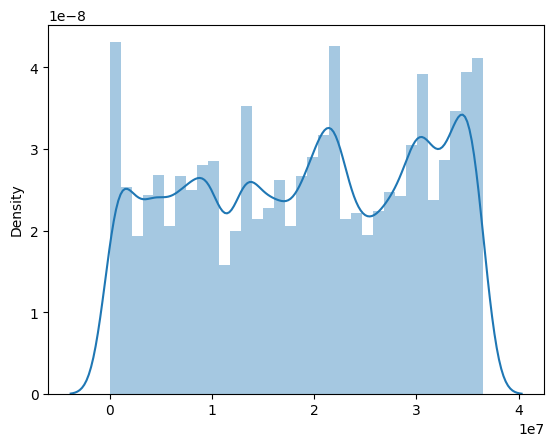

In [21]:
#Univariate Analysis
sns.distplot(x = df['id'])
plt.show()

/tmp/ipykernel_31671/225107835.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x = df['host_id'])


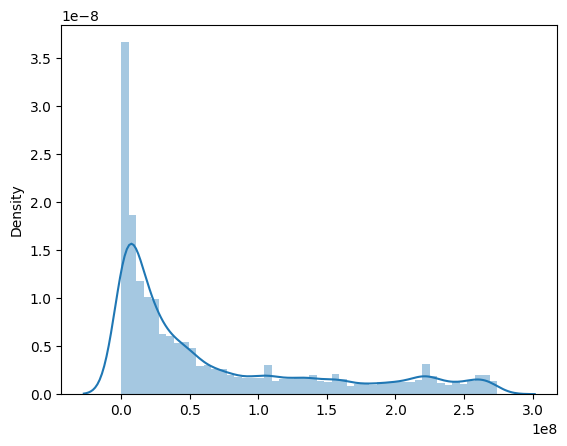

In [22]:
sns.distplot(x = df['host_id'])
plt.show()

/tmp/ipykernel_31671/3745046146.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x = df['price'])


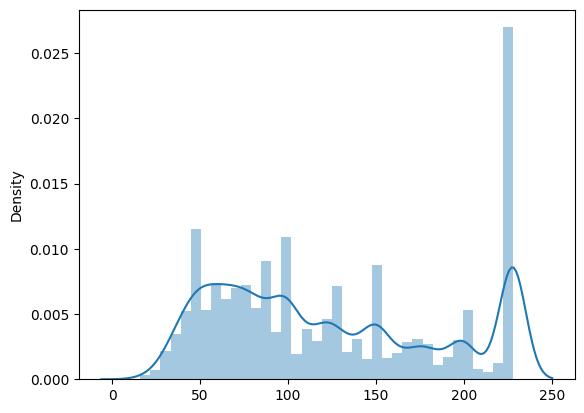

In [23]:
sns.distplot(x = df['price'])
plt.show()

/tmp/ipykernel_31671/2805389597.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x = df['minimum_nights'])


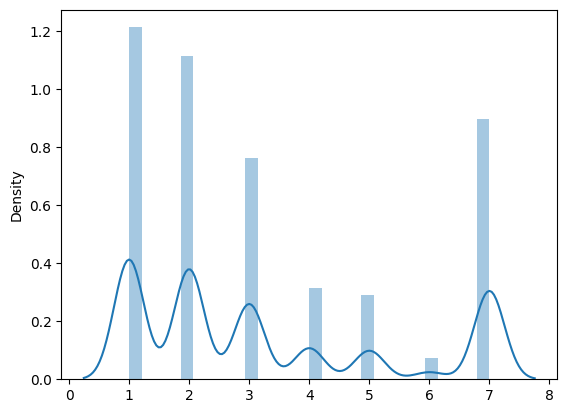

In [24]:
sns.distplot(x = df['minimum_nights'])
plt.show()

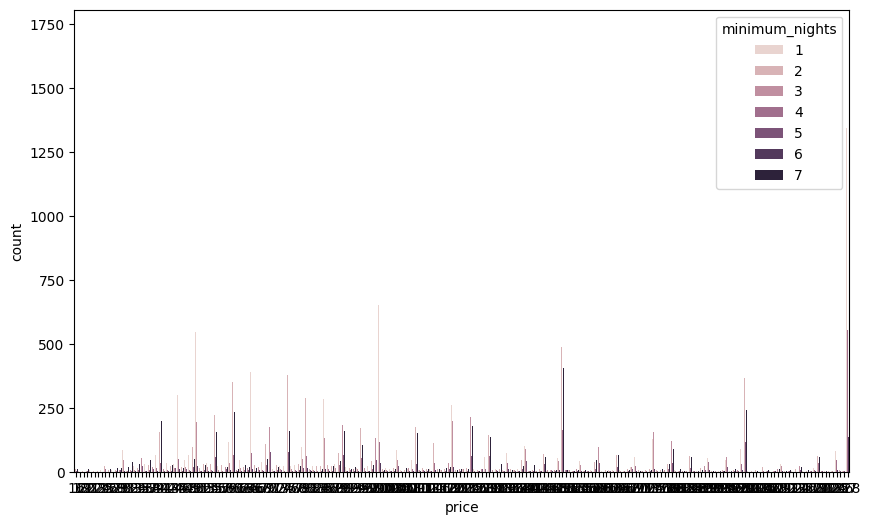

In [25]:
#Bivariated Analysis
plt.figure(figsize = (10,6))
sns.countplot(x = df['price'], hue = "minimum_nights", data = df)
plt.show()

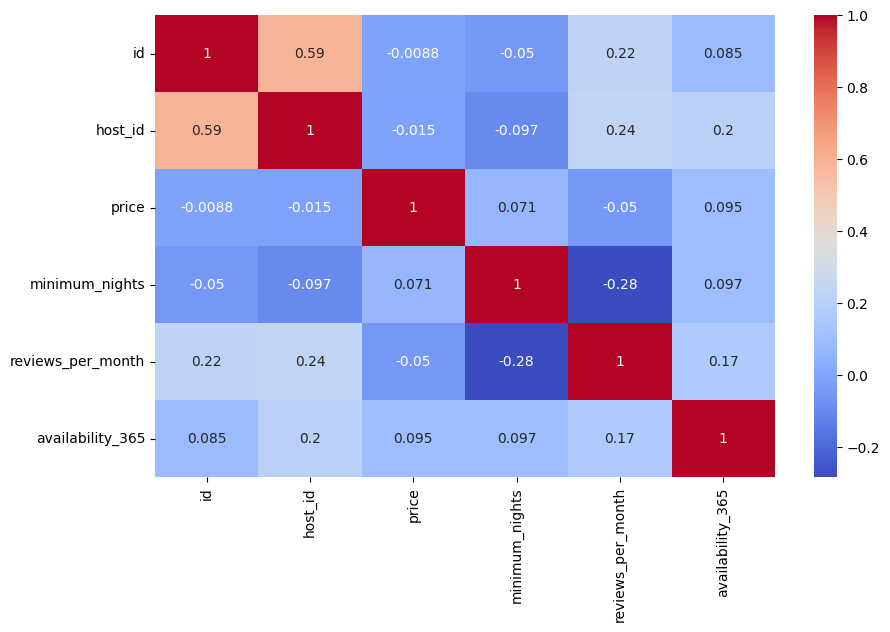

In [26]:
#Multivariated Analysis
plt.figure(figsize = (10,6))
sns.heatmap(df.corr(numeric_only = True), annot = True,  cmap = 'coolwarm')
plt.show()

In [27]:
#Separate X(independent variable) and Y(dependent/target variable)
X = df.drop(['minimum_nights'], axis=1)
y = df['minimum_nights']

In [28]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.20, random_state=42)

In [29]:
#Linear Regression
from sklearn.linear_model import LinearRegression

X_train = X_train[['price']]

model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [30]:
y_pred = model.predict(X_test[['price']])

In [31]:
print(y_pred)

[3.17282868 3.03169377 3.24698431 ... 3.12737845 3.50533295 3.25894489]


In [32]:
results = pd.DataFrame({'Actual': y_test, 'Perdicted': y_pred})
print(results)

       Actual  Perdicted
879         3   3.172829
44383       7   3.031694
15394       2   3.246984
43230       2   3.505333
16332       2   3.435962
...       ...        ...
20477       2   3.474235
44969       1   3.199142
36577       1   3.127378
11477       2   3.505333
1023        3   3.258945

[9779 rows x 2 columns]


In [33]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("Mean Squared Test", mse)
print("R-squared Score", r2)

Mean Squared Test 4.716222651365526
R-squared Score 0.004826245084673109


In [34]:
new_student = pd.DataFrame({'price': [6]})
predicted_price = model.predict(new_student)
print("Predicted Price:", predicted_price)

Predicted Price: [2.97428296]


In [35]:
#Converting objective to numerical dtype so the machine can understand
df.select_dtypes(include = 'object').columns

Index(['host_name', 'neighbourhood', 'room_type'], dtype='object')

In [36]:
df = pd.get_dummies(df, columns = ['host_name', 'neighbourhood', 'room_type'], drop_first = True, dtype = int)
df.head()

,id,host_id,price,minimum_nights,reviews_per_month,availability_365,host_name_'Cil,host_name_(Ari) HENRY LEE,host_name_(Email hidden by Airbnb),host_name_(Mary) Haiy,...,neighbourhood_Williamsbridge,neighbourhood_Williamsburg,neighbourhood_Willowbrook,neighbourhood_Windsor Terrace,neighbourhood_Woodhaven,neighbourhood_Woodlawn,neighbourhood_Woodrow,neighbourhood_Woodside,room_type_Private room,room_type_Shared room
0,2539,2787,149,1,0.21,365,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1,2595,2845,225,1,0.38,355,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,3647,4632,150,3,0.72,365,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
3,3831,4869,89,1,4.64,194,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,5022,7192,80,7,0.10,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Columns: 11680 entries, id to room_type_Shared room
dtypes: float64(1), int64(11679)
memory usage: 4.3 GB


In [38]:
X = df.drop("price", axis = 1)
y = df["price"]

In [39]:
print(X.shape)
print(y.shape)

(48895, 11679)
(48895,)
